# 04 · Multi-image training

Notebooks 02 and 03 trained on a single image. This notebook checks that the
data pipeline works and that PaletteNet learns from many images at once, before
running the full training on a GPU.

This is a pipeline check, not a benchmark: one seed, small images (128 px), a
small subset of COCO val2017 and few steps, so it runs on a CPU. The usage floor
is now averaged over the batch, so a tone may be absent from a simple image as
long as other images in the batch use it.

Questions:

1. Do batches arrive correctly (shape, range, color images only)?
2. Does the reconstruction loss go down when training on many images?
3. With the batch-level floor, are all tones used somewhere in each batch?
4. On images the network never saw, are the tone maps and recoloring sensible?

In [1]:
import os
import time
from pathlib import Path

from dotenv import load_dotenv

load_dotenv()

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import transforms

from aquarelab.data import find_images, make_loader, prepare_batch
from aquarelab.losses import (
    entropy_loss,
    palette_from_weights,
    reconstruct,
    reconstruction_loss,
    usage_floor_loss,
)
from aquarelab.model import PaletteNet
from aquarelab.recolor import assign_by_luminance, hex_to_lab, lab_to_rgb, recolor

os.makedirs("figures", exist_ok=True)
os.makedirs("../checkpoints", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [2]:
DATA_ROOT = "../datasets/coco/val2017"
TEST_IMAGE = "data/florest.jpg"  # never used in training

TRAIN_IMAGES = 1000
HOLDOUT_IMAGES = 8
IMAGE_SIZE = 128
BATCH_SIZE = 8
STEPS = 300
LOG_EVERY = 20
SEED = 0

NUM_TONES = 8
LR = 1e-3
ENTROPY_WEIGHT = 0.01
FLOOR_WEIGHT = 1.0
MIN_USAGE = 0.02       # floor used by the loss, averaged over the batch
DEAD_THRESHOLD = 0.01  # a tone owning less than 1% of the pixels is considered unused

new_palette = hex_to_lab([
    "#264653", "#2a9d8f", "#8ab17d", "#e9c46a",
    "#f4a261", "#e76f51", "#b56576", "#6d597a",
])

In [3]:
def infinite(loader):
    """Yield batches forever, reshuffling and re-augmenting at every pass."""
    while True:
        yield from loader


def tone_stats(weights):
    """
    weights: (B, K, H, W)
    Returns (tones used per image on average, tones unused across the whole batch).
    A tone is used when it is the strongest tone in at least DEAD_THRESHOLD of the pixels.
    """
    owner = weights.argmax(dim=1)  # (B, H, W)
    owned = F.one_hot(owner, weights.shape[1]).float().mean(dim=(1, 2))  # (B, K)
    used_per_image = (owned >= DEAD_THRESHOLD).sum(dim=1).float().mean().item()
    unused_in_batch = int((owned.mean(dim=0) < DEAD_THRESHOLD).sum())
    return used_per_image, unused_in_batch


def l1_lab(lab_a, lab_b):
    scale = np.array([1 / 100, 1 / 128, 1 / 128])
    return np.abs((lab_a - lab_b) * scale).mean()


def moving_average(values, window=10):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

Training images: 1000 | batches per epoch: 125
First batch loaded in 0.25s
Batch shape: (8, 3, 128, 128) | min 0.000 | max 1.000


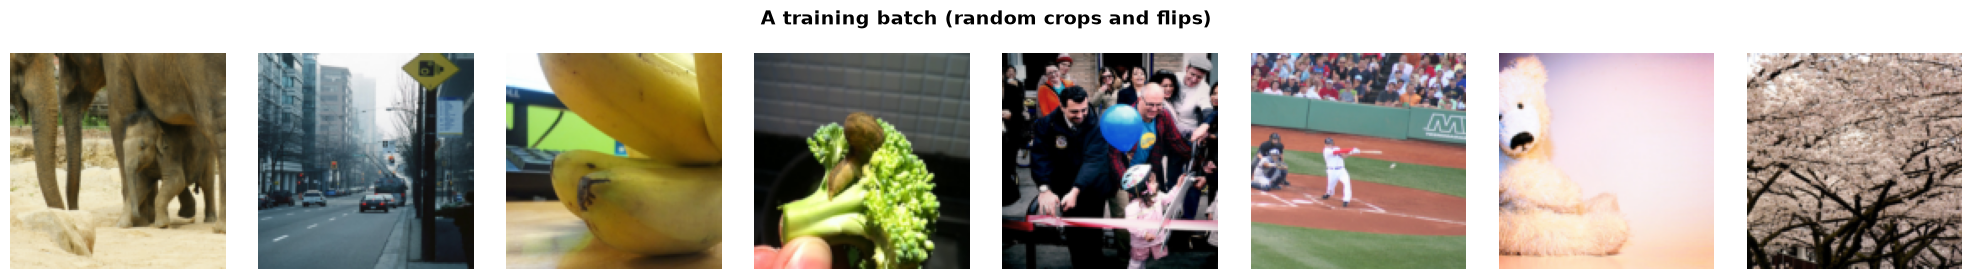

In [4]:
train_loader = make_loader(
    DATA_ROOT,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE,
    train=True,
    max_images=TRAIN_IMAGES,
    seed=SEED,
)
print(f"Training images: {len(train_loader.dataset)} | batches per epoch: {len(train_loader)}")

start = time.perf_counter()
sample = next(iter(train_loader))
print(f"First batch loaded in {time.perf_counter() - start:.2f}s")
print(f"Batch shape: {tuple(sample.shape)} | min {sample.min():.3f} | max {sample.max():.3f}")

fig, axes = plt.subplots(1, BATCH_SIZE, figsize=(2.5 * BATCH_SIZE, 2.8))
for ax, image in zip(axes, sample):
    ax.imshow(image.permute(1, 2, 0).numpy())
    ax.axis("off")
fig.suptitle("A training batch (random crops and flips)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("figures/04_training_batch.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
torch.manual_seed(SEED)
model = PaletteNet(num_tones=NUM_TONES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

history = {"recon": [], "used_per_image": [], "unused_in_batch": []}
model.train()
start = time.perf_counter()

for step, rgb in zip(range(STEPS), infinite(train_loader)):
    net_input, lab = prepare_batch(rgb.to(device))
    weights = model(net_input)
    palette = palette_from_weights(lab, weights)
    recon = reconstruct(weights, palette)

    rec_loss = reconstruction_loss(lab, recon)
    loss = (
        rec_loss
        + ENTROPY_WEIGHT * entropy_loss(weights)
        + FLOOR_WEIGHT * usage_floor_loss(weights, min_usage=MIN_USAGE)
    )
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    used, unused = tone_stats(weights.detach())
    history["recon"].append(rec_loss.item())
    history["used_per_image"].append(used)
    history["unused_in_batch"].append(unused)

    if step % LOG_EVERY == 0 or step == STEPS - 1:
        per_step = (time.perf_counter() - start) / (step + 1)
        print(
            f"step {step:4d} | recon {rec_loss.item():.4f} | tones per image {used:.1f} "
            f"| unused in batch {unused} | {per_step:.2f}s/step"
        )

torch.save(model.state_dict(), "../checkpoints/04_multi_image.pt")

step    0 | recon 0.0965 | tones per image 5.9 | unused in batch 1 | 5.87s/step
step   20 | recon 0.0609 | tones per image 4.8 | unused in batch 3 | 0.41s/step
step   40 | recon 0.0408 | tones per image 4.1 | unused in batch 2 | 0.28s/step
step   60 | recon 0.0395 | tones per image 4.4 | unused in batch 3 | 0.23s/step
step   80 | recon 0.0569 | tones per image 4.8 | unused in batch 3 | 0.21s/step
step  100 | recon 0.0270 | tones per image 4.5 | unused in batch 3 | 0.19s/step
step  120 | recon 0.0472 | tones per image 4.2 | unused in batch 3 | 0.18s/step
step  140 | recon 0.0424 | tones per image 5.0 | unused in batch 3 | 0.17s/step
step  160 | recon 0.0350 | tones per image 4.6 | unused in batch 3 | 0.15s/step
step  180 | recon 0.0442 | tones per image 4.6 | unused in batch 3 | 0.15s/step
step  200 | recon 0.0406 | tones per image 5.2 | unused in batch 2 | 0.14s/step
step  220 | recon 0.0371 | tones per image 5.0 | unused in batch 3 | 0.13s/step
step  240 | recon 0.0471 | tones per ima

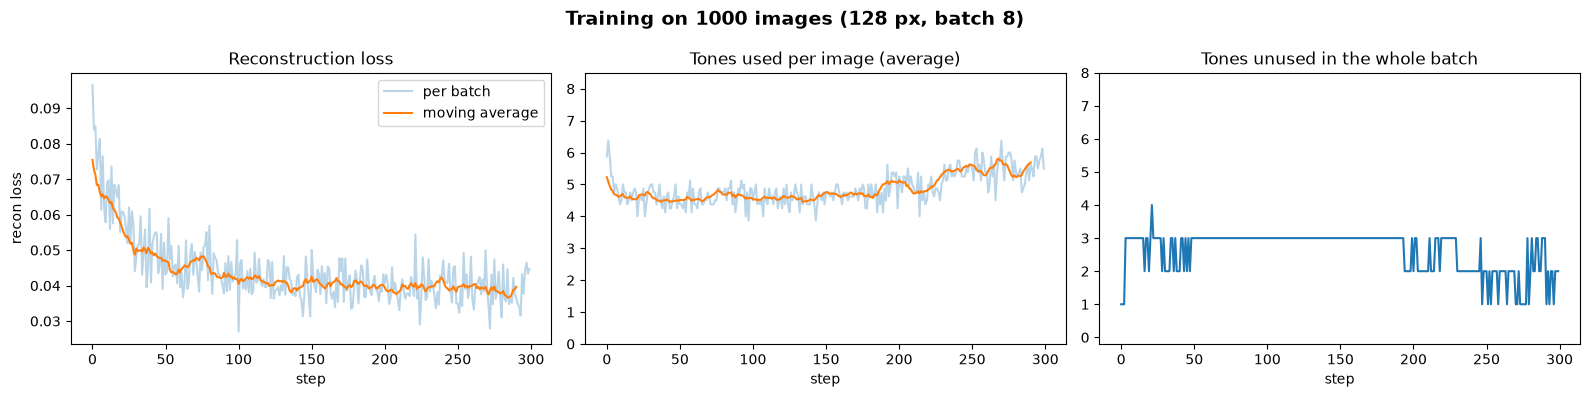

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(history["recon"], alpha=0.3, label="per batch")
axes[0].plot(moving_average(history["recon"]), label="moving average")
axes[0].set_title("Reconstruction loss")
axes[0].set_ylabel("recon loss")
axes[0].legend()

axes[1].plot(history["used_per_image"], alpha=0.3)
axes[1].plot(moving_average(history["used_per_image"]))
axes[1].set_title("Tones used per image (average)")
axes[1].set_ylim(0, NUM_TONES + 0.5)

axes[2].plot(history["unused_in_batch"])
axes[2].set_title("Tones unused in the whole batch")
axes[2].set_ylim(-0.2, NUM_TONES)

for ax in axes:
    ax.set_xlabel("step")

fig.suptitle(
    f"Training on {len(train_loader.dataset)} images ({IMAGE_SIZE} px, batch {BATCH_SIZE})",
    fontsize=14, fontweight="bold",
)
plt.tight_layout()
plt.savefig("figures/04_training_curves.png", dpi=120, bbox_inches="tight")
plt.show()

In [7]:
holdout_paths = find_images(DATA_ROOT, max_images=TRAIN_IMAGES + HOLDOUT_IMAGES)[TRAIN_IMAGES:]
eval_paths = holdout_paths + [Path(TEST_IMAGE)]

eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE, antialias=True),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
])
eval_rgb = torch.stack(
    [eval_transform(Image.open(p).convert("RGB")) for p in eval_paths]
).to(device)

model.eval()
with torch.no_grad():
    net_input, lab = prepare_batch(eval_rgb)
    weights = model(net_input)
    palette = palette_from_weights(lab, weights)
    recon = reconstruct(weights, palette)

results = []
for i, path in enumerate(eval_paths):
    image_np = eval_rgb[i].permute(1, 2, 0).cpu().numpy()
    weights_np = weights[i].permute(1, 2, 0).cpu().numpy()
    palette_np = palette[i].cpu().numpy()
    recon_lab = recon[i].permute(1, 2, 0).cpu().numpy()
    usage = weights_np.mean(axis=(0, 1))
    owned = np.bincount(weights_np.argmax(axis=-1).ravel(), minlength=NUM_TONES)
    owned = owned / owned.sum()
    
    matched = assign_by_luminance(palette_np, new_palette, usage=owned, min_usage=DEAD_THRESHOLD)
    results.append({
        "name": path.stem,
        "image": image_np,
        "weights": weights_np,
        "palette": palette_np,
        "usage": usage,
        "owned": owned,
        "recon_rgb": lab_to_rgb(recon_lab),
        "recon_l1": l1_lab(lab[i].permute(1, 2, 0).cpu().numpy(), recon_lab),
        "tones_used": int((owned >= DEAD_THRESHOLD).sum()),
        "recolored": recolor(image_np, weights_np, palette_np, matched),
    })

for r in results:
    print(f"{r['name']:<16} | recon L1 {r['recon_l1']:.4f} | tones used {r['tones_used']}")

holdout = results[:-1]
print("-" * 46)
print(f"Holdout mean recon L1: {np.mean([r['recon_l1'] for r in holdout]):.4f}")
print(f"Holdout mean tones used: {np.mean([r['tones_used'] for r in holdout]):.1f}")

000000119516     | recon L1 0.0379 | tones used 3
000000119641     | recon L1 0.0355 | tones used 7
000000119677     | recon L1 0.0324 | tones used 7
000000119828     | recon L1 0.0438 | tones used 4
000000119911     | recon L1 0.0301 | tones used 6
000000119995     | recon L1 0.0940 | tones used 5
000000120420     | recon L1 0.0510 | tones used 7
000000120572     | recon L1 0.0310 | tones used 5
florest          | recon L1 0.0289 | tones used 4
----------------------------------------------
Holdout mean recon L1: 0.0444
Holdout mean tones used: 5.5


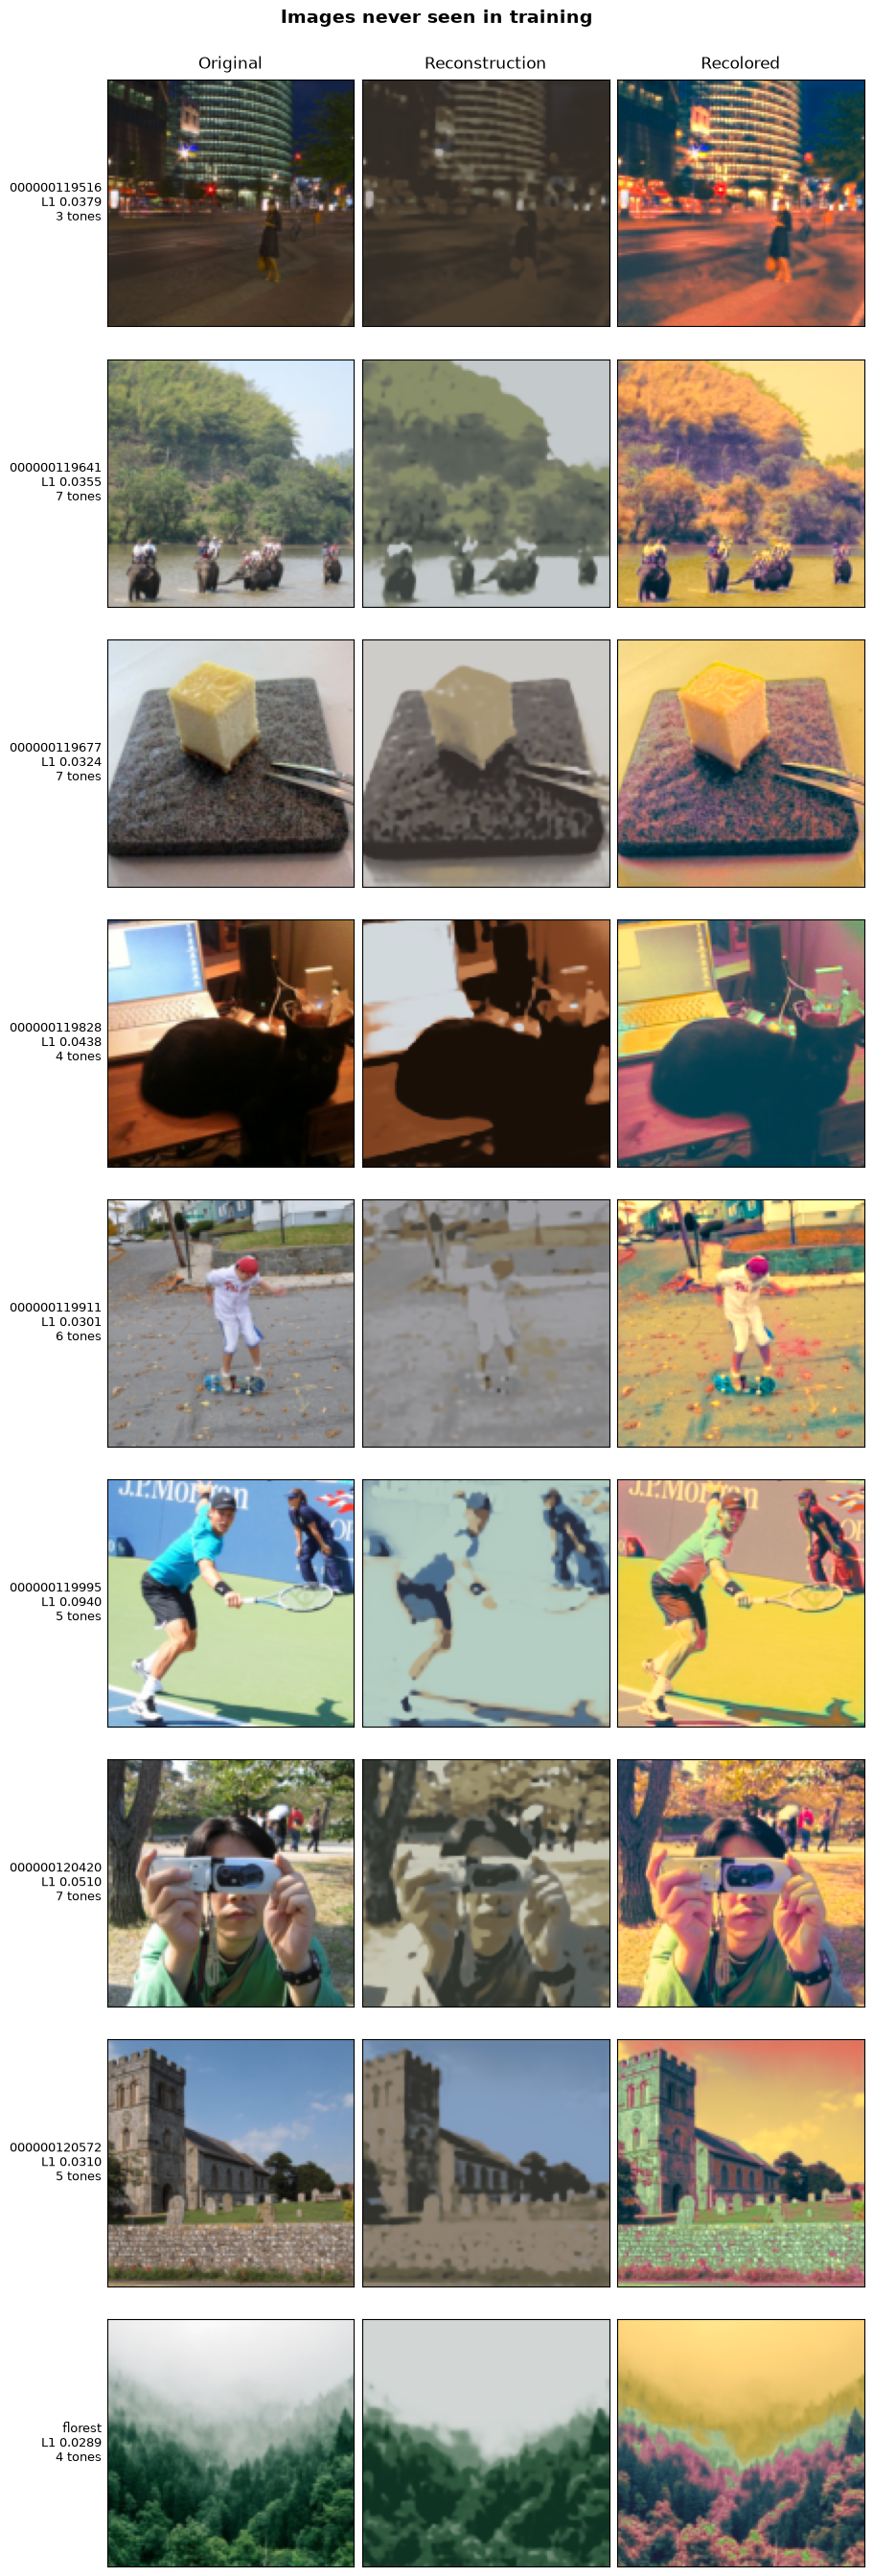

In [8]:
fig, axes = plt.subplots(
    len(results), 3, figsize=(9, 3 * len(results)), layout="constrained"
)
for row, r in zip(axes, results):
    row[0].imshow(r["image"])
    row[1].imshow(r["recon_rgb"])
    row[2].imshow(r["recolored"])
    row[0].set_ylabel(
        f"{r['name']}\nL1 {r['recon_l1']:.4f}\n{r['tones_used']} tones",
        rotation=0, ha="right", va="center", fontsize=9,
    )
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])

for ax, title in zip(axes[0], ["Original", "Reconstruction", "Recolored"]):
    ax.set_title(title, fontsize=12, pad=8)

fig.suptitle("Images never seen in training", fontsize=14, fontweight="bold")
fig.get_layout_engine().set(h_pad=0.15)
plt.savefig("figures/04_unseen_results.png", dpi=120, bbox_inches="tight")
plt.show()

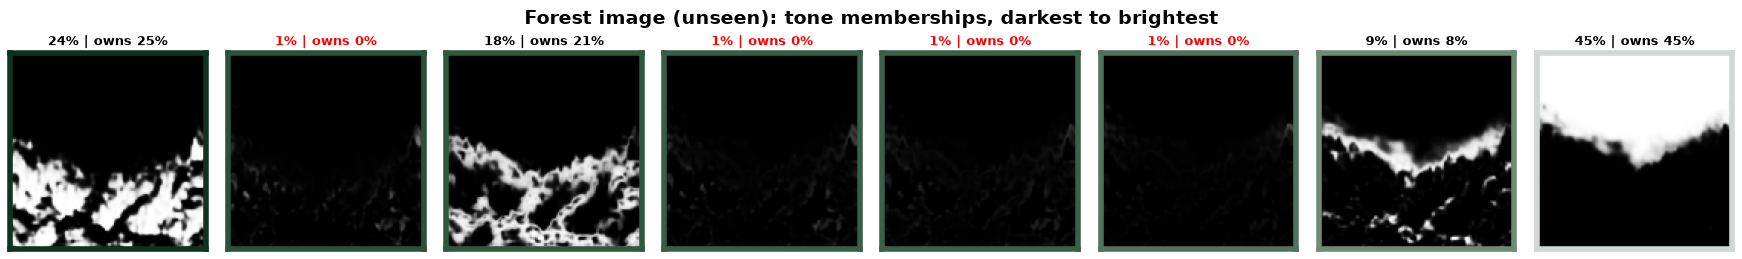

In [9]:
forest = results[-1]
order = np.argsort(forest["palette"][:, 0])  # darkest to brightest

fig, axes = plt.subplots(1, NUM_TONES, figsize=(2.2 * NUM_TONES, 2.6))
for ax, tone in zip(axes, order):
    ax.imshow(forest["weights"][..., tone], cmap="gray", vmin=0, vmax=1)
    swatch = lab_to_rgb(forest["palette"][tone][None, None, :])[0, 0]
    is_unused = forest["owned"][tone] < DEAD_THRESHOLD
    ax.set_title(
        f"{forest['usage'][tone]:.0%} | owns {forest['owned'][tone]:.0%}",
        color="red" if is_unused else "black",
        fontweight="bold",
        fontsize=9,
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_edgecolor(swatch)
        spine.set_linewidth(4)

fig.suptitle(
    "Forest image (unseen): tone memberships, darkest to brightest",
    fontsize=14, fontweight="bold",
)
plt.tight_layout()
plt.savefig("figures/04_forest_tone_maps.png", dpi=120, bbox_inches="tight")
plt.show()

## Conclusions

**The pipeline works.** Batches arrive as expected: color images, random crops
and flips, values in [0, 1]. At 128 px with a batch of 8, 300 steps take about
3.5 minutes on CPU (0.68 s/step) and about 36 seconds on an RTX 5060 Ti. The GPU
is only about 6x faster here because images are still loaded one at a time on
the CPU, so the GPU waits for data. Parallel data loading is needed for the full
training run.

**Results differ between CPU and GPU with the same seed.** The GPU computes in
a different order, and small rounding differences change the training path.
All trends below held on both devices. From now on, runs that are compared
against each other must use the same device.

**The network learns from many images.** Reconstruction loss drops from 0.096
to about 0.04 in the first 100 steps, then plateaus. The per-batch curve is
noisy because each batch holds different images, some harder than others.

**It generalizes to unseen images.** Tone maps follow real objects: the cat is
one dark region, the cake separates from the plate, the church tower separates
from the sky, the tennis player separates from the court. On the forest image,
which was never used in training, the fog became a single tone (45%) with one
transition band (9%), instead of the three layers seen in notebooks 02 and 03.
Recoloring keeps texture on every image.

**The floor was fooled again, now at batch level.** Three tones stay unused
across the whole batch for most of training. On the forest image, four tones
have about 1% average weight but own 0% of the pixels, so it effectively uses
4 tones. The floor measures average weight, and the network meets it by
spreading a faint weight instead of giving those tones a region.

**More training may help.** Near the end, unused tones start dropping from 3 to
between 1 and 2, and tones per image rise from about 4.5 to about 5.5. The
network started recruiting new tones right when training stopped.

**Saturated colors are the weakest case.** The tennis image has the worst error
(L1 0.094, about twice the holdout mean of 0.044). The bright cyan shirt and
green court collapse into the same pale blue. With few active tones and very
varied images, there is no tone left for rare saturated colors.